In [1]:
import numpy as np, pandas as pd, tensorflow as tf, time
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score

tf.keras.utils.set_random_seed(42)

splits = pd.read_csv(r"D:\AgriVision\data\splits.csv")
train_df = splits[splits.split == "train"]
val_df = splits[splits.split == "val"]
test_df = splits[splits.split == "test"]

classes = ["BrownRust", "Healthy", "Mildew", "Septoria", "YellowRust"]
c2i = {c: i for i, c in enumerate(classes)}
IMG, BATCH = 224, 32


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return img, label


def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["path"].values, frame["label"].map(c2i).values))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


train_ds = make_ds(train_df, True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

y_train = train_df["label"].map(c2i).values
w = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(w))
print("Ready:", len(train_df), len(val_df), len(test_df))

Ready: 699 150 150



=== Training CNN from scratch ===
Epoch 1/15


d:\AgriVision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 - 207s - 9s/step - accuracy: 0.1431 - loss: 1.6177 - val_accuracy: 0.1600 - val_loss: 1.6082
Epoch 2/15
22/22 - 168s - 8s/step - accuracy: 0.1617 - loss: 1.6037 - val_accuracy: 0.2533 - val_loss: 1.5768
Epoch 3/15
22/22 - 214s - 10s/step - accuracy: 0.2489 - loss: 1.5849 - val_accuracy: 0.3267 - val_loss: 1.5306
Epoch 4/15
22/22 - 190s - 9s/step - accuracy: 0.2890 - loss: 1.5436 - val_accuracy: 0.2867 - val_loss: 1.5091
Epoch 5/15
22/22 - 176s - 8s/step - accuracy: 0.3176 - loss: 1.5023 - val_accuracy: 0.3800 - val_loss: 1.4009
Epoch 6/15
22/22 - 145s - 7s/step - accuracy: 0.3963 - loss: 1.4653 - val_accuracy: 0.4200 - val_loss: 1.3867
Epoch 7/15
22/22 - 203s - 9s/step - accuracy: 0.3848 - loss: 1.4541 - val_accuracy: 0.3800 - val_loss: 1.3868
Epoch 8/15
22/22 - 198s - 9s/step - accuracy: 0.3705 - loss: 1.4439 - val_accuracy: 0.4133 - val_loss: 1.4121
Epoch 9/15
22/22 - 143s - 7s/step - accuracy: 0.3648 - loss: 1.4556 - val_accuracy: 0.4067 - val_loss: 1.4751
Epoch 10/15
22/22 - 

d:\AgriVision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 - 38s - 2s/step - accuracy: 0.2346 - loss: 1.8811 - val_accuracy: 0.2533 - val_loss: 1.7079
Epoch 2/10
22/22 - 23s - 1s/step - accuracy: 0.3691 - loss: 1.5316 - val_accuracy: 0.3533 - val_loss: 1.5054
Epoch 3/10
22/22 - 41s - 2s/step - accuracy: 0.3820 - loss: 1.4544 - val_accuracy: 0.3667 - val_loss: 1.4775
Epoch 4/10
22/22 - 22s - 1s/step - accuracy: 0.4034 - loss: 1.3658 - val_accuracy: 0.4267 - val_loss: 1.3576
Epoch 5/10
22/22 - 41s - 2s/step - accuracy: 0.4793 - loss: 1.2538 - val_accuracy: 0.4800 - val_loss: 1.3128
Epoch 6/10
22/22 - 23s - 1s/step - accuracy: 0.5007 - loss: 1.2257 - val_accuracy: 0.4867 - val_loss: 1.2574
Epoch 7/10
22/22 - 40s - 2s/step - accuracy: 0.5093 - loss: 1.1655 - val_accuracy: 0.4800 - val_loss: 1.2646
Epoch 8/10
22/22 - 42s - 2s/step - accuracy: 0.5250 - loss: 1.1271 - val_accuracy: 0.5533 - val_loss: 1.2025
Epoch 9/10
22/22 - 41s - 2s/step - accuracy: 0.5751 - loss: 1.1369 - val_accuracy: 0.5133 - val_loss: 1.1949
Epoch 10/10
22/22 - 22s - 1s/s

d:\AgriVision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 - 79s - 4s/step - accuracy: 0.3047 - loss: 1.5598 - val_accuracy: 0.4200 - val_loss: 1.4316
Epoch 2/8
22/22 - 53s - 2s/step - accuracy: 0.4549 - loss: 1.2829 - val_accuracy: 0.4733 - val_loss: 1.2782
Epoch 3/8
22/22 - 53s - 2s/step - accuracy: 0.5637 - loss: 1.1416 - val_accuracy: 0.4667 - val_loss: 1.2358
Epoch 4/8
22/22 - 82s - 4s/step - accuracy: 0.5980 - loss: 1.0669 - val_accuracy: 0.5533 - val_loss: 1.1464
Epoch 5/8
22/22 - 82s - 4s/step - accuracy: 0.6309 - loss: 0.9713 - val_accuracy: 0.5800 - val_loss: 1.1183
Epoch 6/8
22/22 - 82s - 4s/step - accuracy: 0.6366 - loss: 0.9456 - val_accuracy: 0.5667 - val_loss: 1.1014
Epoch 7/8
22/22 - 59s - 3s/step - accuracy: 0.6695 - loss: 0.8917 - val_accuracy: 0.5933 - val_loss: 1.0504
Epoch 8/8
22/22 - 84s - 4s/step - accuracy: 0.6810 - loss: 0.8506 - val_accuracy: 0.6133 - val_loss: 1.0089
EfficientNetB0 test accuracy: 0.5133
                    model  test_accuracy  macro_F1  epochs  minutes
MobileNetV2 (notebook 04)         0.6600 

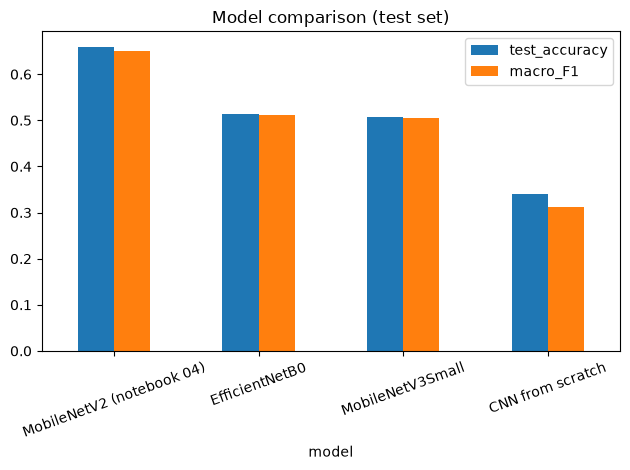

In [2]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])


def build_scratch():
    inp = keras.Input((IMG, IMG, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(5, activation="softmax")(x)
    return keras.Model(inp, out)


def build_transfer(base):
    base.trainable = False
    inp = keras.Input((IMG, IMG, 3))
    x = augment(inp)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(5, activation="softmax")(x)
    return keras.Model(inp, out)


candidates = {
    "CNN from scratch": (build_scratch, 15),
    "MobileNetV3Small": (lambda: build_transfer(keras.applications.MobileNetV3Small(
        input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")), 10),
    "EfficientNetB0": (lambda: build_transfer(keras.applications.EfficientNetB0(
        input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")), 8),
}

rows = []
for name, (builder, epochs) in candidates.items():
    print("\n=== Training", name, "===")
    m = builder()
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    m.fit(train_ds, validation_data=val_ds, epochs=epochs,
          class_weight=class_weights, verbose=2)
    y_true, y_pred = [], []
    for x, y in test_ds:
        y_true.extend(y.numpy())
        y_pred.extend(np.argmax(m.predict(x, verbose=0), axis=1))
    acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
    f1 = f1_score(y_true, y_pred, average="macro")
    rows.append({"model": name, "test_accuracy": round(acc, 4),
                 "macro_F1": round(f1, 4), "epochs": epochs,
                 "minutes": round((time.time() - t0) / 60, 1)})
    print(name, "test accuracy:", round(acc, 4))

# add the MobileNetV2 result from notebook 04 for comparison
rows.append({"model": "MobileNetV2 (notebook 04)", "test_accuracy": 0.66,
             "macro_F1": 0.65, "epochs": 10, "minutes": None})

results = pd.DataFrame(rows).sort_values("test_accuracy", ascending=False)
print(results.to_string(index=False))
results.to_csv(r"D:\AgriVision\data\model_comparison.csv", index=False)

results.plot.bar(x="model", y=["test_accuracy", "macro_F1"], rot=20)
plt.title("Model comparison (test set)")
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
print(pd.read_csv(r"D:\AgriVision\data\model_comparison.csv").to_string(index=False))

                    model  test_accuracy  macro_F1  epochs  minutes
MobileNetV2 (notebook 04)         0.6600    0.6500      10      NaN
           EfficientNetB0         0.5133    0.5106       8     10.0
         MobileNetV3Small         0.5067    0.5056      10      5.7
         CNN from scratch         0.3400    0.3117      15     44.9
